<a href="https://colab.research.google.com/github/aabha25/nexus/blob/main/XGBOOST_Final50.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np

In [3]:
# df = pd.read_csv('/content/drive/MyDrive/Flattened_Input_XGBoost_WithAgeSexDecline_16-8-25.csv')
# df.shape
df = pd.read_csv('/content/drive/MyDrive/trainxgboost.csv')
df.shape

(305, 399)

In [4]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,389,390,391,392,393,394,395,396,397,398
0,75,0,30.728432,0.0,7.730588,5.025456,1.823457,0.0,9.790758,0.0,...,3.256823,0.0,0.0,6.174289,24.584297,0.0,0.0,8.00,16.00,2
1,83,0,33.105865,0.0,14.344643,5.134811,4.778924,0.0,10.616479,0.0,...,0.000000,0.0,0.0,11.245796,24.674185,0.0,0.0,4.67,7.67,2
2,79,1,46.937030,0.0,19.009192,3.151681,6.104017,0.0,18.568846,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
3,76,0,40.971775,0.0,15.296716,5.286087,5.741526,0.0,14.200731,0.0,...,0.000000,0.0,0.0,12.689952,25.582218,0.0,0.0,4.00,6.00,2
4,86,0,33.429400,0.0,13.165087,4.160962,5.787603,0.0,10.437432,0.0,...,2.256289,0.0,0.0,10.187354,25.039909,0.0,0.0,2.00,4.00,2


In [4]:
#increamental cha random search

import xgboost as xgb
from sklearn.model_selection import RandomizedSearchCV
import numpy as np

# Prepare your data
X = df.iloc[:, :398].replace(-1, np.nan).values
y = df.iloc[:, 398]

# param_grid = {
#     'n_estimators': [10, 20, 50],  # low because we'll train incrementally
#     'max_depth': [3, 5, 7],
#     'learning_rate': [0.01, 0.05, 0.1],
#     'subsample': [0.7, 1.0],
#     'colsample_bytree': [0.7, 1.0],
#     'gamma': [0, 0.1],
#     'min_child_weight': [1, 3],
#     'reg_alpha': [0, 0.1],
#     'reg_lambda': [1, 2]
# }

param_grid = {
    'n_estimators': [50, 100, 200],          # Increase for more robust trees even incrementally
    'max_depth': [3, 5, 7, 9],               # Add deeper trees if data is complex
    'learning_rate': [0.005, 0.01, 0.05, 0.1], # Include slower rates for finer updates
    'subsample': [0.5, 0.7, 0.9, 1.0],       # More variability in sampling data rows
    'colsample_bytree': [0.5, 0.7, 0.9, 1.0],# More variability in sampling features
    'gamma': [0, 0.1, 0.3, 0.5],             # Try stronger pruning options
    'min_child_weight': [1, 3, 5, 7],        # Regularize deeper splits
    'reg_alpha': [0, 0.1, 0.5, 1],           # L1 regularization to avoid overfitting
    'reg_lambda': [1, 1.5, 2, 5]             # L2 regularization
}


model = xgb.XGBClassifier(
    eval_metric='mlogloss',
    use_label_encoder=False
)

random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=30,
    scoring='accuracy',
    cv=3,
    verbose=1,
    n_jobs=-1,
    random_state=42
)

random_search.fit(X, y)

best_params = random_search.best_params_
print("Best hyperparameters:", best_params)


Fitting 3 folds for each of 30 candidates, totalling 90 fits


/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [16:19:39] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best hyperparameters: {'subsample': 0.7, 'reg_lambda': 5, 'reg_alpha': 0.1, 'n_estimators': 50, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.01, 'gamma': 0.1, 'colsample_bytree': 0.7}


In [5]:
#increamental model

# # batch_size = 100
# n_samples = X.shape[0]
# n_batches = n_samples // batch_size
# X = df.iloc[:, :398].replace(-1, np.nan).values
# y = df.iloc[:, 398]
# Initialize model with best hyperparameters
incremental_model = xgb.XGBClassifier(
    **best_params,
    eval_metric='mlogloss',
    use_label_encoder=False
)

prev_model = None

for i in range(1,7):
     X_test = np.full((305, 398), np.nan)
     X_test[:, :66*i+2] = X[:, :66*i+2]  # <-- take first 66 * i columns from X
     y = df.iloc[:, 398]



     incremental_model.fit(
        X_test, y,
        xgb_model=prev_model
     )

     prev_model = incremental_model.get_booster()


/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [16:19:46] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [16:19:47] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [16:19:48] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [16:19:49] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [6]:

def mask_all_after(X, n_unmasked=66):
    X_masked = X.copy()
    X_masked[:, n_unmasked:] = np.nan
    return X_masked

# Masked data: only first 66 features present
for i in range(1,7):
  X_masked = mask_all_after(X, n_unmasked=66*i+2)

  # Continue training the existing best_model on masked data
  incremental_model.fit(
      X_masked, y,
      xgb_model=incremental_model.get_booster()
  )

/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [16:19:58] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [16:19:59] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [16:20:00] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [16:20:01] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [9]:
# for j in range(3):
#   for i in range(1, 7):
#     X_masked = mask_all_after(X, n_unmasked=66*i)

#     # Continue training the existing best_model on masked data
#     incremental_model.fit(
#         X_masked, y,
#         xgb_model=incremental_model.get_booster()
#     )

In [7]:

# X = df.iloc[:, :398].replace(-1, np.nan).values
# y = df.iloc[:, 398]
for j in range(2):
  for i in range(1, 7):
      X_masked = mask_all_after(X, n_unmasked=66*i+2)

      # Continue training the existing best_model on masked data
      incremental_model.fit(
          X_masked, y,
          xgb_model=incremental_model.get_booster()
      )

/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [16:20:12] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [16:20:14] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [16:20:18] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [16:20:20] WARNING: /workspace/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
/usr/local/lib/python3.11/dist-packages/xgboost/training.py:183: UserWarning: [16:20:21] WARNING: /w

In [8]:
from sklearn.metrics import accuracy_score

for i in range(1, 7):
    X_test = np.full((305, 398), np.nan)
    X_test[:, :66*i+2] = X[:, :66*i+2]
    preds = incremental_model.predict(X_test)
    acc = accuracy_score(y[:], preds)
    print(f"Accuracy with first {66*i} features: {acc}")

Accuracy with first 66 features: 0.6327868852459017
Accuracy with first 132 features: 0.9245901639344263
Accuracy with first 198 features: 0.9770491803278688
Accuracy with first 264 features: 0.9836065573770492
Accuracy with first 330 features: 0.9901639344262295
Accuracy with first 396 features: 0.9967213114754099


In [12]:
#TESTING

In [9]:
dftest = pd.read_csv('/content/drive/MyDrive/testxgboost.csv')
dftest.shape

(77, 399)

In [10]:
Xt = dftest.iloc[:, :398].replace(-1, np.nan).values
yt = dftest.iloc[:, 398]

from sklearn.metrics import accuracy_score

for i in range(1, 7):
    X_test = np.full((77, 398), np.nan)
    X_test[:, :66*i+2] = Xt[:, :66*i+2]
    preds = incremental_model.predict(X_test)
    acc = accuracy_score(yt[:], preds)
    print(f"Accuracy with first {66*i} features: {acc}")

Accuracy with first 66 features: 0.5714285714285714
Accuracy with first 132 features: 0.6883116883116883
Accuracy with first 198 features: 0.6753246753246753
Accuracy with first 264 features: 0.6363636363636364
Accuracy with first 330 features: 0.6883116883116883
Accuracy with first 396 features: 0.6883116883116883


In [15]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, average_precision_score
from sklearn.preprocessing import label_binarize
import numpy as np

Xt = dftest.iloc[:, :398].replace(-1, np.nan).values
yt = dftest.iloc[:, 398]
sum=0
sum2=0
sum3=0
sum4=0
acc_list=[]
pr_list=[]
roc_list=[]
f1_list=[]
n_classes = len(np.unique(yt))  # should be 3 in your case

# Binarize labels for ROC/PR (one-vs-rest)
yt_bin = label_binarize(yt, classes=range(n_classes))

for i in range(1, 7):
    # Create partial test set
    X_test = np.full((Xt.shape[0], Xt.shape[1]), np.nan)
    X_test[:, :66*i+2] = Xt[:, :66*i+2]

    # Predictions
    preds = incremental_model.predict(X_test)
    preds_proba = incremental_model.predict_proba(X_test)

    # Accuracy
    acc = accuracy_score(yt, preds)

    # F1 Score (macro = average across classes)
    f1 = f1_score(yt, preds, average='macro')

    # ROC AUC (one-vs-rest, macro average)
    roc_auc = roc_auc_score(yt_bin, preds_proba, average='macro', multi_class='ovr')

    # PR AUC (macro average)
    pr_auc = average_precision_score(yt_bin, preds_proba, average='weighted')
    acc_list.append(acc)
    roc_list.append(roc_auc)
    pr_list.append(pr_auc)
    print(f"With first {66*i} features:")
    print(f"  Accuracy: {acc:.3f}")
    print(f"  F1-score (macro): {f1:.3f}")
    print(f"  ROC AUC (macro): {roc_auc:.3f}")
    print(f"  PR AUC (macro): {pr_auc:.3f}\n")

print("accuracy ",sum/6)
print("roc ",sum2/6)
print("pr ",sum3/6)


With first 66 features:
  Accuracy: 0.571
  F1-score (macro): 0.242
  ROC AUC (macro): 0.771
  PR AUC (macro): 0.682

With first 132 features:
  Accuracy: 0.688
  F1-score (macro): 0.593
  ROC AUC (macro): 0.794
  PR AUC (macro): 0.714

With first 198 features:
  Accuracy: 0.675
  F1-score (macro): 0.562
  ROC AUC (macro): 0.801
  PR AUC (macro): 0.707

With first 264 features:
  Accuracy: 0.636
  F1-score (macro): 0.555
  ROC AUC (macro): 0.803
  PR AUC (macro): 0.711

With first 330 features:
  Accuracy: 0.688
  F1-score (macro): 0.624
  ROC AUC (macro): 0.850
  PR AUC (macro): 0.768

With first 396 features:
  Accuracy: 0.688
  F1-score (macro): 0.615
  ROC AUC (macro): 0.861
  PR AUC (macro): 0.775

accuracy  0.0
roc  0.0
pr  0.0


In [16]:
import numpy as np
from sklearn.metrics import f1_score
from sklearn.preprocessing import label_binarize
sum=0
def optimal_f1_thresholds_independent(y_true, y_proba, thresholds=np.linspace(0,1,101)):
    """
    Optimize F1-score by finding best threshold independently per class (one-vs-rest).
    Much faster than full joint grid search.

    Parameters:
    - y_true: array of shape (n_samples,), true class labels
    - y_proba: array of shape (n_samples, n_classes), predicted probabilities
    - thresholds: list/array of thresholds to search

    Returns:
    - best_f1: macro F1-score using the chosen per-class thresholds
    - best_thresholds: list of best threshold per class
    """
    n_classes = y_proba.shape[1]
    yt_bin = label_binarize(y_true, classes=range(n_classes))

    best_thresholds = []

    # Step 1: find best threshold for each class independently
    for c in range(n_classes):
        best_t, best_c_f1 = 0.5, 0
        for t in thresholds:
            preds = (y_proba[:, c] >= t).astype(int)
            f1 = f1_score(yt_bin[:, c], preds)
            if f1 > best_c_f1:
                best_c_f1, best_t = f1, t
        best_thresholds.append(best_t)

    # Step 2: apply thresholds together
    preds = []
    for row in y_proba:
        activated = [i for i, p in enumerate(row) if p >= best_thresholds[i]]
        if len(activated) == 0:
            preds.append(np.argmax(row))   # fallback: highest prob
        elif len(activated) == 1:
            preds.append(activated[0])
        else:
            preds.append(np.argmax(row))   # tie -> highest prob
    best_f1 = f1_score(y_true, preds, average="weighted")

    return best_f1, best_thresholds


# ================== Example Usage ==================

for i in range(1, 7):
    # Mask test set features
    X_test = np.full((Xt.shape[0], Xt.shape[1]), np.nan)
    X_test[:, :66*i+2] = Xt[:, :66*i+2]

    # Get predicted probabilities
    y_proba = incremental_model.predict_proba(X_test)

    # Optimize thresholds per class (fast version)
    best_f1, best_thresholds = optimal_f1_thresholds_independent(yt, y_proba)
    f1_list.append(best_f1)
    print(f"With first {66*i} features:")
    print(f"  Best Macro F1: {best_f1:.3f}")
#     print(f"  Optimal thresholds per class: {best_thresholds}\n")

print("avg:" , sum/6)

With first 66 features:
  Best Macro F1: 0.566
With first 132 features:
  Best Macro F1: 0.666
With first 198 features:
  Best Macro F1: 0.683
With first 264 features:
  Best Macro F1: 0.679
With first 330 features:
  Best Macro F1: 0.725
With first 396 features:
  Best Macro F1: 0.740
avg: 0.0


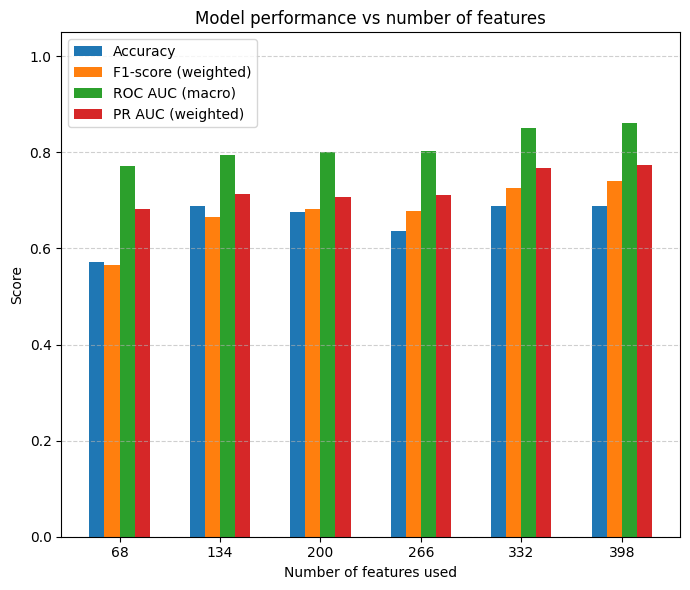

['68', '134', '200', '266', '332', '398']
[0.5714285714285714, 0.6883116883116883, 0.6753246753246753, 0.6363636363636364, 0.6883116883116883, 0.6883116883116883]
[0.5657142857142857, 0.665513903318116, 0.6831746658116706, 0.6788439703800205, 0.7254963161511093, 0.7395429272336382]
[np.float64(0.7712915523471744), np.float64(0.7942586520337717), np.float64(0.8013376193848681), np.float64(0.803258744511735), np.float64(0.8498658140105508), np.float64(0.8613489862742255)]
[np.float64(0.6818199399455775), np.float64(0.7143394129796216), np.float64(0.7066651778404683), np.float64(0.7111412692358181), np.float64(0.7684814872043655), np.float64(0.7748216680725849)]


In [26]:
import matplotlib.pyplot as plt
import numpy as np
features_used = ["68", "134", "200", "266", "332", "398"]

# Convert to numpy for easier plotting
features = np.array(features_used)
x = np.arange(len(features))  # x positions for groups

# Width of each bar
bar_width = 0.15

plt.figure(figsize=(7,6))
plt.bar(x - 1.5*bar_width, acc_list, width=bar_width, label="Accuracy")
plt.bar(x - 0.5*bar_width, f1_list, width=bar_width, label="F1-score (weighted)")
plt.bar(x + 0.5*bar_width, roc_list, width=bar_width, label="ROC AUC (macro)")
plt.bar(x + 1.5*bar_width, pr_list, width=bar_width, label="PR AUC (weighted)")

plt.xticks(x, features)
plt.xlabel("Number of features used")
plt.ylabel("Score")
plt.title("Model performance vs number of features")
plt.ylim(0, 1.05)   # since metrics are between 0 and 1
plt.legend()
plt.grid(True, linestyle="--", alpha=0.6, axis="y")
plt.tight_layout()
plt.show()

print(features_used)
print(acc_list)
print(f1_list)
print(roc_list)
print(pr_list)
